# Introduction

This notebook is part of the Machine Learning lifecycle for the **Melbourne Housing Market** dataset.  
The goal of this stage is to prepare the dataset for modeling by performing:

- Data preprocessing (dropping irrelevant features, handling outliers, missing values, etc.)
- Feature engineering (encoding, scaling, transformations)
- Building reproducible **pipelines** for training and inference

We assume that data cleaning and EDA have already been completed.


In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# ML tools
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import (
    VarianceThreshold,
    RFECV,
    SequentialFeatureSelector
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.feature_selection import f_regression, mutual_info_regression,SelectKBest

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## Load the Dataset

We load the cleaned dataset obtained after EDA.  
Ensure the file path points to the latest cleaned version of the dataset.


In [2]:
df_original = pd.read_csv('data/melbourne_housing_cleaned_v1.csv')
df_original.head()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,Northcote,303/231 St Georges Rd,2,u,S,McGrath,12/8/2017,5.3,3070.0,3.0,...,515.0,74.0,1970.0,Darebin City Council,-37.806498,144.992667,Northern Metropolitan,11364.0,Detached Garage,673000.0
1,Bentleigh East,63 Barrington St,3,h,S,Jellis,26/08/2017,13.8,3165.0,3.0,...,515.0,148.0,1960.0,Glen Eira City Council,-37.912970,145.073500,Southern Metropolitan,10969.0,Attached Garage,1372500.0
2,Reservoir,39 Crevelli St,3,h,S,Stockdale,3/9/2017,12.0,3073.0,3.0,...,170.0,128.0,1950.0,Darebin City Council,-37.729240,145.029810,Northern Metropolitan,21650.0,Outdoor Stall,612500.0
3,Jacana,53 Lorraine Cr,3,h,S,YPA,20/05/2017,14.5,3047.0,3.0,...,515.0,148.0,1960.0,Hume City Council,-37.806498,144.992667,Northern Metropolitan,851.0,Attached Garage,515000.0
4,Prahran,93 Charles St,3,h,S,Marshall,28/05/2016,4.5,3181.0,2.0,...,238.0,153.0,1890.0,Stonnington City Council,-37.847600,144.989200,Southern Metropolitan,7717.0,Carport,2180000.0


## Drop Non-Significant Columns

From the EDA stage, we identified certain columns that have little or no predictive power or contain excessive unique values. We will remove those columns to simplify the model and reduce noise.


In [3]:
cols_to_drop = ["Address","ParkingArea","Rooms","Postcode", "Date"]

df_original.drop(columns=cols_to_drop, inplace=True)
print(f"Dropped columns: {cols_to_drop}")

Dropped columns: ['Address', 'ParkingArea', 'Rooms', 'Postcode', 'Date']


## Handle Outliers

After reviewing the EDA results and visualizing distributions using box plots:

- The columns **`Landsize`**, **`BuildingArea`**, and **`Price`** appeared to be**highly skewed** with extreme right-side values.  
  We will apply a **log transformation** to these columns to reduce skewness and normalize their distributions.

- The columns **`Distance`**, **`Car`**, and **`Bathroom`**, though slightly skewed, do **not exhibit extreme outliers**.  
  Their value ranges (max values around 49, 7, and 7 respectively) are reasonable, so we will **retain them as-is**.

- The **`YearBuilt`** column, though skewed, naturally reflects the distribution of house construction years  
  and will also be left unchanged.

> *Note:* Because log(0) is undefined, we will add +1 to each column before applying the transformation to handle any zero values safely.



In [4]:
has_nan = df_original.isna().any().any()
print("Contains NaN values:", has_nan)

Contains NaN values: False


In [5]:
# Columns identified as highly skewed
skewed_cols = ['Landsize', 'BuildingArea']

# Apply log(1 + x) transformation to reduce skewness
for col in skewed_cols:
    if col in df_original.columns:
        df_original[f'Log_{col}'] = np.log1p(df_original[col])  # log1p handles 0 values gracefully

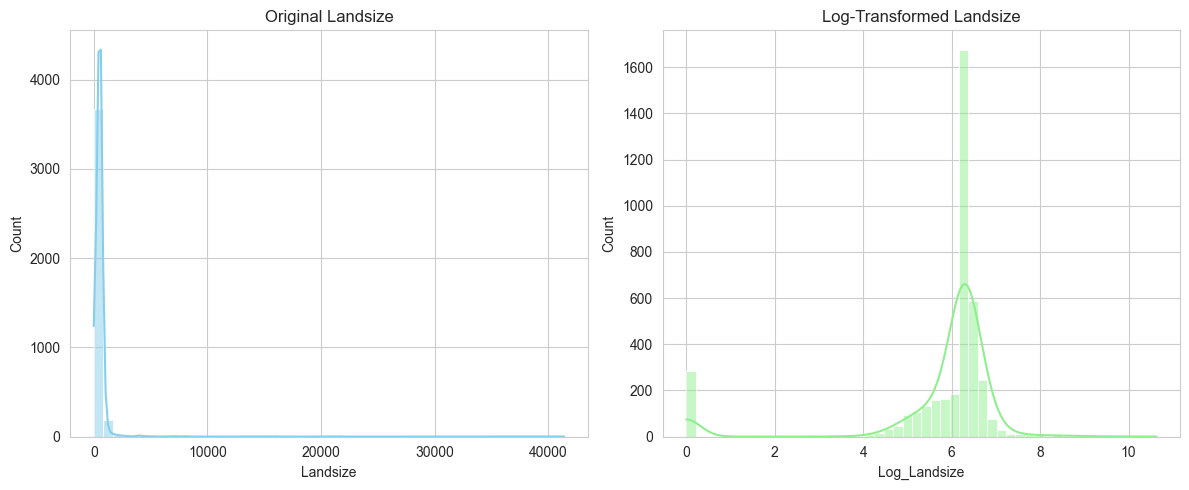

Landsize -> Skewness before: 27.88, after log-transform: -2.75



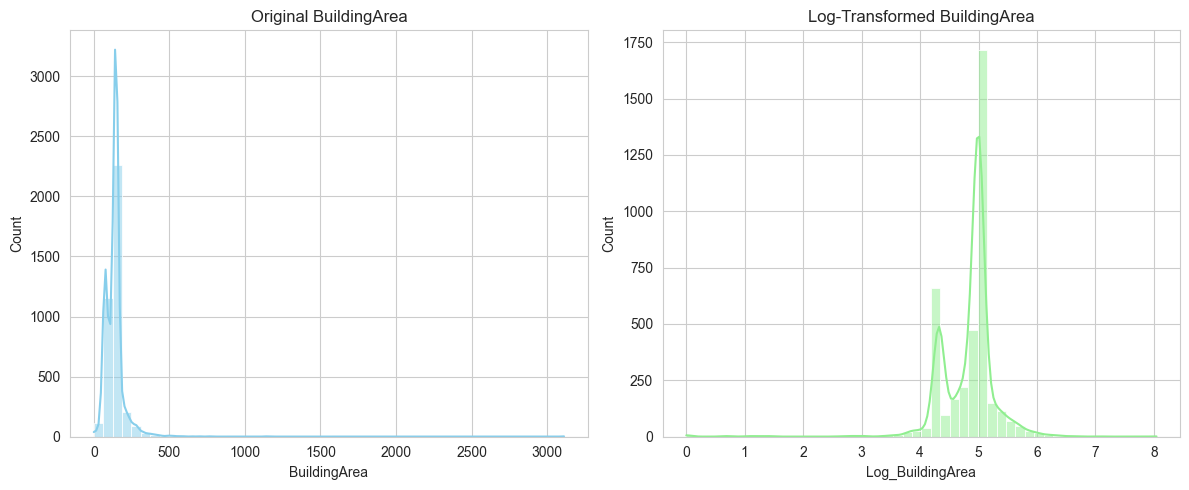

BuildingArea -> Skewness before: 16.39, after log-transform: -3.11



In [6]:
for col in skewed_cols:
    plt.figure(figsize=(12, 5))

    # Original
    plt.subplot(1, 2, 1)
    sns.histplot(df_original[col], bins=50, kde=True, color='skyblue')
    plt.title(f'Original {col}')
    plt.xlabel(col)

    # Log-transformed
    plt.subplot(1, 2, 2)
    sns.histplot(df_original[f'Log_{col}'], bins=50, kde=True, color='lightgreen')
    plt.title(f'Log-Transformed {col}')
    plt.xlabel(f'Log_{col}')

    plt.tight_layout()
    plt.show()

    # Print skewness before and after
    original_skew = df_original[col].skew()
    log_skew = df_original[f'Log_{col}'].skew()
    print(f"{col} -> Skewness before: {original_skew:.2f}, after log-transform: {log_skew:.2f}\n")

## FEATURE ENGINEERING
Feature engineering aims to enhance the dataset by transforming existing variables into more informative or model-friendly forms.  
In this stage, we perform **feature transformation**, focusing primarily on encoding categorical variables so they can be effectively used in machine learning models.

Different categorical features have different characteristics — some have only a few possible values (low cardinality), while others have hundreds (high cardinality).  
Hence, a **mixed encoding strategy** is used to handle each feature appropriately.

### 1. Feature Transformation
Different encoding strategies are used based on the **cardinality** and **semantic meaning** of each categorical variable:

| Feature | Unique | Encoding Method | Reason |
|----------|----------|----------------|--------|
| Suburb | 295 | Frequency / Target | High cardinality, location-based |
| SellerG | 195 | Frequency / Target | High cardinality, weak effect |
| Type | 3 | One-Hot | Low cardinality, categorical |
| Method | 5 | One-Hot | Low cardinality, sale type |
| CouncilArea | 32 | Frequency / Target | Medium cardinality, location |
| Regionname | 8 | One-Hot | Low cardinality, regional grouping |

This mixed encoding approach balances interpretability and efficiency, preventing excessive feature expansion while preserving meaningful relationships.

In [7]:
encoded_df = df_original.copy()

# ====== 1. Frequency Encoding ======
# Suitable for features with many unique values like Suburb, SellerG, CouncilArea
for col in ["Suburb", "SellerG","CouncilArea"]:
    freq_map = encoded_df[col].value_counts().to_dict()
    encoded_df[f"{col}_enc"] = encoded_df[col].map(freq_map)
    print(f"Applied frequency encoding to '{col}'")

# ====== 2. One-Hot Encoding ======
# For low-cardinality categorical features
onehot_features = ["Type", "Method", "Regionname"]
onehot_encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

# Fit and transform
onehot_encoded = onehot_encoder.fit_transform(encoded_df[onehot_features])

# Get feature names
feature_names = onehot_encoder.get_feature_names_out(onehot_features)

# Create DataFrame with encoded features
onehot_df = pd.DataFrame(onehot_encoded, columns=feature_names, index=encoded_df.index)

# Drop original columns and concatenate encoded ones
encoded_df = encoded_df.drop(columns=onehot_features)
encoded_df = pd.concat([encoded_df, onehot_df], axis=1)

print(f"Applied one-hot encoding to {onehot_features}")

# Drop encoded columns
encoded_df = encoded_df.drop(columns=['Suburb', 'SellerG', 'CouncilArea'])

Applied frequency encoding to 'Suburb'
Applied frequency encoding to 'SellerG'
Applied frequency encoding to 'CouncilArea'
Applied one-hot encoding to ['Type', 'Method', 'Regionname']


In [8]:
encoded_df.head()

,Distance,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Latitude,Longtitude,Propertycount,...,Method_SA,Method_SP,Method_VB,Regionname_Eastern Victoria,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria
0,5.3,3.0,1.0,2.0,515.0,74.0,1970.0,-37.806498,144.992667,11364.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,13.8,3.0,1.0,2.0,515.0,148.0,1960.0,-37.912970,145.073500,10969.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,12.0,3.0,1.0,1.0,170.0,128.0,1950.0,-37.729240,145.029810,21650.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,14.5,3.0,1.0,2.0,515.0,148.0,1960.0,-37.806498,144.992667,851.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,4.5,2.0,2.0,2.0,238.0,153.0,1890.0,-37.847600,144.989200,7717.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


 1. **Frequency Encoding**
   - Replaces each category with its occurrence count.
   - Retains useful information about category prevalence without inflating feature space.
   - Example: If *Suburb A* appears 300 times and *Suburb B* appears 10 times, their encoded values will be 300 and 10.

 2. **Target Encoding**
   - Replaces each category with the mean value of the target (`Price`) within that category.
   - Captures the direct relationship between categorical values and the target variable.
   - Applied carefully to avoid data leakage (ideally within cross-validation in the full pipeline).

 3. **One-Hot Encoding**
   - Expands low-cardinality categorical features into separate binary columns.
   - Keeps interpretability while maintaining model compatibility.
   - Used for `Type`, `Method`, and `Regionname`, which each have only a few possible values.


In [9]:
has_nan = encoded_df.isna().any().any()
print("Contains NaN values:", has_nan)

Contains NaN values: False


In [10]:
encoded_df.shape

(3895, 29)

### 2. Feature Creation

Feature creation involves generating new variables derived from existing ones to expose hidden patterns or improve model performance.  
For housing data, this step often includes combining, scaling, or deriving features that better reflect property characteristics and market dynamics.

In this dataset, we create new features that describe:
- **Age of the property**
- **Land and building proportions**
- **Distance-based attributes**

These engineered features help the model understand structural efficiency, property condition, and location context.


In [11]:
features_df = df_original.copy()

# --- Property Age ---
# Convert YearBuilt to property age (as of latest date in dataset)
latest_year = features_df['YearBuilt'].max()
features_df['PropertyAge'] = latest_year - features_df['YearBuilt']

# --- House Size Indicator ---
# Combine building and land dimensions into one general property size measure
features_df["TotalArea"] = features_df["Landsize"] + features_df["BuildingArea"]
features_df["Log_TotalArea"] = np.log1p(features_df["TotalArea"])

**Feature: Is_CBD**

**Description:**
The Is_CBD column is a binary feature that indicates whether a property is located within 5 kilometers of Melbourne’s Central Business District (CBD).

- 1 → Property is within 5 km of the CBD (central area)
- 0 → Property is beyond 5 km from the CBD

**Rationale:**
Property prices in Melbourne are strongly influenced by proximity to the city center. Houses located closer to the CBD typically have:

- Better access to jobs, transport, and amenities
- Higher demand and limited land availability
Consequently, higher prices per square meter. By converting the continuous Distance variable into this binary flag, we capture the “CBD premium”, the price boost associated with being in or near the central urban zone.

**Why it’s important:**
- Adds a non-linear perspective to the model that pure distance may not fully capture.
- Helps the model distinguish between prime urban locations and suburban/outer areas, even if two properties are similar in size or age.
- Works well alongside the continuous Distance feature to represent both the overall distance effect and the central location effect.

In [12]:
# Create is_CBD binary feature
features_df['Is_CBD'] = (features_df['Distance'] < 5).astype(int)

In [13]:
features_df.head()

,Suburb,Type,Method,SellerG,Distance,Bedroom,Bathroom,Car,Landsize,BuildingArea,...,Longtitude,Regionname,Propertycount,Price,Log_Landsize,Log_BuildingArea,PropertyAge,TotalArea,Log_TotalArea,Is_CBD
0,Northcote,u,S,McGrath,5.3,3.0,1.0,2.0,515.0,74.0,...,144.992667,Northern Metropolitan,11364.0,673000.0,6.246107,4.317488,47.0,589.0,6.380123,0
1,Bentleigh East,h,S,Jellis,13.8,3.0,1.0,2.0,515.0,148.0,...,145.073500,Southern Metropolitan,10969.0,1372500.0,6.246107,5.003946,57.0,663.0,6.498282,0
2,Reservoir,h,S,Stockdale,12.0,3.0,1.0,1.0,170.0,128.0,...,145.029810,Northern Metropolitan,21650.0,612500.0,5.141664,4.859812,67.0,298.0,5.700444,0
3,Jacana,h,S,YPA,14.5,3.0,1.0,2.0,515.0,148.0,...,144.992667,Northern Metropolitan,851.0,515000.0,6.246107,5.003946,57.0,663.0,6.498282,0
4,Prahran,h,S,Marshall,4.5,2.0,2.0,2.0,238.0,153.0,...,144.989200,Southern Metropolitan,7717.0,2180000.0,5.476464,5.036953,127.0,391.0,5.971262,1


In [14]:
has_nan = features_df.isna().any().any()
print("Contains NaN values:", has_nan)

Contains NaN values: False


In [15]:
cleaned_df = features_df.copy()
cleaned_df = cleaned_df.drop(columns=['BuildingArea','Landsize','YearBuilt','TotalArea']) # Drop transformed columns
cleaned_df.to_csv('data/melbourne_housing_cleaned_featEngr.csv', index=False)

In [16]:
cleaned_df.head()

,Suburb,Type,Method,SellerG,Distance,Bedroom,Bathroom,Car,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,Price,Log_Landsize,Log_BuildingArea,PropertyAge,Log_TotalArea,Is_CBD
0,Northcote,u,S,McGrath,5.3,3.0,1.0,2.0,Darebin City Council,-37.806498,144.992667,Northern Metropolitan,11364.0,673000.0,6.246107,4.317488,47.0,6.380123,0
1,Bentleigh East,h,S,Jellis,13.8,3.0,1.0,2.0,Glen Eira City Council,-37.912970,145.073500,Southern Metropolitan,10969.0,1372500.0,6.246107,5.003946,57.0,6.498282,0
2,Reservoir,h,S,Stockdale,12.0,3.0,1.0,1.0,Darebin City Council,-37.729240,145.029810,Northern Metropolitan,21650.0,612500.0,5.141664,4.859812,67.0,5.700444,0
3,Jacana,h,S,YPA,14.5,3.0,1.0,2.0,Hume City Council,-37.806498,144.992667,Northern Metropolitan,851.0,515000.0,6.246107,5.003946,57.0,6.498282,0
4,Prahran,h,S,Marshall,4.5,2.0,2.0,2.0,Stonnington City Council,-37.847600,144.989200,Southern Metropolitan,7717.0,2180000.0,5.476464,5.036953,127.0,5.971262,1


## Feature Selection
In this section, we aim to identify which feature selection technique performs best when predicting house prices using various regression models.
Feature selection helps reduce noise, remove redundant variables, and improve both model interpretability and generalization performance. 
### Methodology

**Target and Features**
The target variable is Price (log-transformed using np.log1p to reduce skewness).
All other variables are used as predictors (X).

**Data Splitting and Evaluation**
We applied k-fold cross-validation (k=5) to obtain robust and unbiased performance estimates.
The evaluation metric used is the R² score, which measures how well the model explains the variance in the target variable.

**Feature Selection Techniques Tested**
- Variance Threshold: Removes features with low variance, assuming they carry little information.
- ANOVA F-test: Selects features most linearly correlated with the target variable.
- Mutual Information: Captures both linear and non-linear dependencies between features and the target.
- RFECV (Recursive Feature Elimination with Cross-Validation): Iteratively removes the least important features based on model coefficients and re-evaluates performance.
- Sequential Forward Selection: Gradually adds features that improve model performance, using cross-validation to validate each step.

**Regression Models Compared**
- Linear Regression
- Lasso Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor

Each feature selection method was wrapped in a Pipeline with scaling and the chosen regression model, then evaluated via cross-validation.

In [17]:
exp_df = encoded_df.copy()
# --- Property Age ---
# Convert YearBuilt to property age (as of latest date in dataset)
latest_year = exp_df['YearBuilt'].max()
exp_df['PropertyAge'] = latest_year - exp_df['YearBuilt']

# --- House Size Indicator ---
# Combine building and land dimensions into one general property size measure
exp_df["TotalArea"] = exp_df["Landsize"] + exp_df["BuildingArea"]
exp_df["Log_TotalArea"] = np.log1p(exp_df["TotalArea"])

# Create is_CBD binary feature
exp_df['Is_CBD'] = (exp_df['Distance'] < 5).astype(int)

exp_df.drop(columns=['BuildingArea','Landsize','YearBuilt','TotalArea'])

,Distance,Bedroom,Bathroom,Car,Latitude,Longtitude,Propertycount,Price,Log_Landsize,Log_BuildingArea,...,Regionname_Eastern Victoria,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria,PropertyAge,Log_TotalArea,Is_CBD
0,5.3,3.0,1.0,2.0,-37.806498,144.992667,11364.0,673000.0,6.246107,4.317488,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,47.0,6.380123,0
1,13.8,3.0,1.0,2.0,-37.912970,145.073500,10969.0,1372500.0,6.246107,5.003946,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,57.0,6.498282,0
2,12.0,3.0,1.0,1.0,-37.729240,145.029810,21650.0,612500.0,5.141664,4.859812,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,67.0,5.700444,0
3,14.5,3.0,1.0,2.0,-37.806498,144.992667,851.0,515000.0,6.246107,5.003946,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,57.0,6.498282,0
4,4.5,2.0,2.0,2.0,-37.847600,144.989200,7717.0,2180000.0,5.476464,5.036953,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,127.0,5.971262,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3890,11.2,3.0,1.0,2.0,-37.806498,144.992667,8870.0,620000.0,6.246107,5.003946,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,57.0,6.498282,0
3891,12.1,3.0,1.0,2.0,-37.806498,144.992667,1414.0,643000.0,6.246107,4.317488,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,47.0,6.380123,0
3892,10.5,5.0,3.0,2.0,-37.926150,145.002820,10579.0,3250000.0,6.728629,5.003946,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,57.0,6.891626,0
3893,5.9,3.0,1.0,3.0,-37.772800,144.907600,6567.0,1050000.0,6.285998,5.003946,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,57.0,6.529419,0


In [18]:
# --- Dataset ---
selection_df = exp_df.copy()
y = np.log1p(selection_df['Price'])
X = selection_df.drop(columns=['Price'])

# --- Define cross-validation ---
cv = KFold(n_splits=5, shuffle=True, random_state=0)

# --- Define feature selection methods ---
def get_feature_selectors(base_model):
    return {
        "VarianceThreshold": Pipeline([
            ("scale", StandardScaler()),
            ("select", VarianceThreshold(threshold=0.01)),
            ("reg", base_model)
        ]),
        "ANOVA F-test": Pipeline([
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=f_regression, k=12)),
            ("reg", base_model)
        ]),
        "Mutual Info": Pipeline([
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=mutual_info_regression, k=12)),
            ("reg", base_model)
        ]),
        "RFECV": Pipeline([
            ("scale", StandardScaler()),
            ("rfecv", RFECV(LinearRegression(), step=1, cv=5, scoring="r2")),
            ("reg", base_model)
        ]),
        "Forward Selection": Pipeline([
            ("scale", StandardScaler()),
            ("forward_selection", SequentialFeatureSelector(
                LinearRegression(),
                n_features_to_select=10,
                direction='forward',
                scoring='r2',
                cv=5,
                n_jobs=-1
            )),
            ("reg", base_model)
        ])
    }

# --- Define models ---
models = {
    "LinearRegression": LinearRegression(),
    "Lasso": Lasso(alpha=0.001, max_iter=5000),
    "DecisionTree": DecisionTreeRegressor(random_state=0),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=0)
}

# --- Evaluate all combinations ---
results = []

for model_name, model in models.items():
    print(f"\n=== Evaluating model: {model_name} ===")
    selectors = get_feature_selectors(model)
    
    for sel_name, pipe in selectors.items():
        scores = cross_val_score(pipe, X, y, cv=cv, scoring="r2", n_jobs=-1)
        results.append({
            "Model": model_name,
            "Feature_Selection": sel_name,
            "Mean_R2": np.mean(scores),
            "Std_R2": np.std(scores)
        })

# --- Results DataFrame ---
results_df = pd.DataFrame(results).sort_values(["Mean_R2"], ascending=False).reset_index(drop=True)

print("\nCross-validated results:")
print(results_df)


=== Evaluating model: LinearRegression ===

=== Evaluating model: Lasso ===

=== Evaluating model: DecisionTree ===

=== Evaluating model: RandomForest ===

=== Evaluating model: GradientBoosting ===

Cross-validated results:
               Model  Feature_Selection   Mean_R2    Std_R2
0       RandomForest  VarianceThreshold  0.775828  0.008022
1       RandomForest              RFECV  0.774720  0.007791
2   GradientBoosting  VarianceThreshold  0.764343  0.009109
3   GradientBoosting              RFECV  0.763699  0.009028
4       RandomForest  Forward Selection  0.749332  0.014065
5       RandomForest        Mutual Info  0.749178  0.016352
6       RandomForest       ANOVA F-test  0.746485  0.009377
7   GradientBoosting  Forward Selection  0.744742  0.015643
8   GradientBoosting       ANOVA F-test  0.739087  0.017612
9   GradientBoosting        Mutual Info  0.727231  0.017238
10  LinearRegression  VarianceThreshold  0.658632  0.028068
11             Lasso  VarianceThreshold  0.658357  0.

**Key Observations:**
- Ensemble methods (Random Forest, Gradient Boosting) achieved the highest R² scores (~0.77–0.78).
- Simple methods like Variance Threshold performed surprisingly well, suggesting most features are informative.
- RFECV also performed strongly across models, confirming its ability to adaptively eliminate redundant predictors.
- Complex selectors (Mutual Information, Forward Selection) did not outperform simpler ones, possibly due to dataset structure or limited non-linear dependencies.

**Conclusion**
Based on cross-validated R² performance across all models:
Variance Threshold and RFECV consistently provided the best results.

> **Note**: The feature selection was done on separate cleaned dataset where categorical columns where encoded and the dataset was mostly cleaned.

## Preprocessing Pipeline

In [19]:
from sklearn.impute import SimpleImputer
# ==============================
# 1. Custom Frequency Encoder
# ==============================
from utils import FrequencyEncoder, DataFrameImputer

# ==============================
# 2. Column Setup
# ==============================
freq_cols = ["Suburb", "SellerG", "CouncilArea"]
onehot_cols = ["Type", "Method", "Regionname"]

numeric_cols = [
    "Distance", "Bedroom", "Bathroom", "Car",
    "Propertycount", "Latitude", "Longtitude",
    "PropertyAge", "Log_Landsize", "Log_BuildingArea", "Log_TotalArea", "Is_CBD"
]

# ==============================
# 3. Preprocessing Pipelines
# ==============================
# Frequency encoding pipeline
freq_pipe = Pipeline([
    ("imputer", DataFrameImputer(strategy="most_frequent")),
    ("freq_enc", FrequencyEncoder(cols=freq_cols))
])

onehot_pipe = Pipeline([
    ("imputer", DataFrameImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

num_pipe = Pipeline([
    ("imputer", DataFrameImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("freq", freq_pipe, freq_cols),
    ("onehot", onehot_pipe, onehot_cols),
    ("num", num_pipe, numeric_cols)
])

# ==============================
# 4. Full Feature Selection + Model Pipeline
# ==============================
full_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("variance", VarianceThreshold(threshold=0.01)),
    ("rfecv", "passthrough"), # RFECV(LinearRegression(), step=1, cv=5, scoring="r2", n_jobs=-1)
    ("model", RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1))
])

# Save
joblib.dump(full_pipeline, "artifacts/melbourne_pipeline.pkl")
print(f"Pipeline Saved!!")

Pipeline Saved!!


**Inspecting our preprocess step with different treshhold values**

In [20]:
y = np.log1p(cleaned_df["Price"])
X = cleaned_df.drop(columns=["Price"])

full_pipeline.fit(X, y)

# Extract the preprocessor from the pipeline
preprocessor = full_pipeline.named_steps["preprocess"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()
print(f"Total features before VarianceThreshold: {len(feature_names)}")

var_thresh = full_pipeline.named_steps["variance"]

mask = var_thresh.get_support()  # True = kept, False = dropped

# Kept features
kept_features = np.array(feature_names)[mask]

# Dropped features
dropped_features = np.array(feature_names)[~mask]

print(f"Features kept: {len(kept_features)}")
print(f"Features dropped: {len(dropped_features)}")

print("\nDropped columns due to low variance:")
print(dropped_features)

Total features before VarianceThreshold: 28
Features kept: 24
Features dropped: 4

Dropped columns due to low variance:
['onehot__Method_SA' 'onehot__Regionname_Eastern Victoria'
 'onehot__Regionname_Northern Victoria'
 'onehot__Regionname_Western Victoria']


#### Insights
| Threshhold | Features Kept |Features Dropped | Dropped Columns |
|----------|----------|----------------|--------|
| 0.01 | 24 | 4 | onehot__Method_SA, onehot__Regionname_Eastern Victoria, onehot__Regionname_Northern Victoria, onehot__Regionname_Western Victoria |
| 0.05 | 23 | 5 | onehot__Method_SA, onehot__Regionname_Eastern Victoria onehot__Regionname_Northern Victoria,onehot__Regionname_South-Eastern Metropolitan onehot__Regionname_Western Victoria |
| 0.1 | 21 | 7 | onehot__Type_t, onehot__Method_SA, onehot__Method_VB, onehot__Regionname_Eastern Victoria, onehot__Regionname_Northern Victoria, onehot__Regionname_South-Eastern Metropolitan, onehot__Regionname_Western Victoria |